# <center>**Chapter 23 - Understand Model Behavior During Training by Visualizing Metrics**<center>

## **Mục tiêu**
- Huấn luyện mô hình hồi quy PyTorch trên California Housing.
- Ghi lại MSE, MAE và sai số tuyệt đối lớn nhất trên train/validation sau mỗi epoch.
- Vẽ lịch sử huấn luyện để nhận biết hội tụ, quá khớp hoặc tối ưu chưa ổn định.

`fetch_california_housing` tải dữ liệu ở lần chạy đầu và lưu cache của scikit-learn; bước tải cần kết nối mạng. Tập test được giữ riêng để đánh giá cuối, không dùng để chọn epoch.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
# California Housing là bộ hồi quy được dùng trong chương hướng dẫn.
def find_lab_data_dir() -> Path:
    lab_dir_name = "Buổi thực hành số 7 (Optimizing DL Networks)"
    current = Path.cwd().resolve()
    for root in (current, *current.parents):
        candidates = (
            root / "data",
            root / "code" / "data",
            root / lab_dir_name / "code" / "data",
        )
        for candidate in candidates:
            if (candidate / "pima-indians-diabetes.csv").is_file():
                return candidate
    raise FileNotFoundError("Không tìm thấy thư mục dữ liệu của buổi thực hành số 7.")

housing = fetch_california_housing(data_home=find_lab_data_dir() / "sklearn_cache")
X = housing.data.astype(np.float32)
y = housing.target.astype(np.float32).reshape(-1, 1)

In [3]:
# Tách test trước; validation theo dõi quá trình học, test chỉ đánh giá cuối.
X_train_valid, X_test, y_train_valid, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_valid, y_train_valid, test_size=0.1765, random_state=SEED
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_valid = scaler.transform(X_valid).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
    batch_size=512,
    shuffle=True,
)
X_train_tensor = torch.from_numpy(X_train).to(DEVICE)
y_train_tensor = torch.from_numpy(y_train).to(DEVICE)
X_valid_tensor = torch.from_numpy(X_valid).to(DEVICE)
y_valid_tensor = torch.from_numpy(y_valid).to(DEVICE)
X_test_tensor = torch.from_numpy(X_test).to(DEVICE)
y_test_tensor = torch.from_numpy(y_test).to(DEVICE)

In [4]:
model = nn.Sequential(
    nn.Linear(X_train.shape[1], 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1),
).to(DEVICE)
loss_fn = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

print(f"Mẫu train/validation/test: {len(X_train)}/{len(X_valid)}/{len(X_test)}")
print("Thiết bị:", DEVICE)

Mẫu train/validation/test: 14447/3097/3096
Thiết bị: cpu


## **Thu thập metric trong vòng lặp**

MSE phạt mạnh sai số lớn; MAE dễ diễn giải theo đơn vị mục tiêu; sai số tuyệt đối lớn nhất cho biết trường hợp dự đoán tệ nhất. Các chỉ số train và validation được tính ở chế độ đánh giá nên không cập nhật trọng số.

In [5]:
def regression_metrics(
    targets: torch.Tensor,
    predictions: torch.Tensor,
) -> dict[str, float]:
    errors = predictions - targets
    absolute_errors = errors.abs()
    return {
        "mse": errors.square().mean().item(),
        "mae": absolute_errors.mean().item(),
        "max_ae": absolute_errors.max().item(),
    }

history = {
    "train_mse": [],
    "valid_mse": [],
    "train_mae": [],
    "valid_mae": [],
    "valid_max_ae": [],
}
best_valid_mse = float("inf")
best_state = None
n_epochs = 50

for epoch in range(n_epochs):
    model.train()
    for features, targets in train_loader:
        features, targets = features.to(DEVICE), targets.to(DEVICE)
        loss = loss_fn(model(features), targets)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.inference_mode():
        train_metrics = regression_metrics(y_train_tensor, model(X_train_tensor))
        valid_metrics = regression_metrics(y_valid_tensor, model(X_valid_tensor))

    history["train_mse"].append(train_metrics["mse"])
    history["valid_mse"].append(valid_metrics["mse"])
    history["train_mae"].append(train_metrics["mae"])
    history["valid_mae"].append(valid_metrics["mae"])
    history["valid_max_ae"].append(valid_metrics["max_ae"])

    if valid_metrics["mse"] < best_valid_mse:
        best_valid_mse = valid_metrics["mse"]
        best_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in model.state_dict().items()
        }

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1:02d}/{n_epochs}: "
            f"train MSE={train_metrics['mse']:.4f}, "
            f"validation MSE={valid_metrics['mse']:.4f}, "
            f"validation MAE={valid_metrics['mae']:.4f}"
        )

if best_state is None:
    raise RuntimeError("Không có trạng thái mô hình tốt nhất để khôi phục.")

Epoch 10/50: train MSE=0.4764, validation MSE=0.4766, validation MAE=0.4958
Epoch 20/50: train MSE=0.3786, validation MSE=0.3728, validation MAE=0.4340
Epoch 30/50: train MSE=0.3398, validation MSE=0.3380, validation MAE=0.4091
Epoch 40/50: train MSE=0.3180, validation MSE=0.3208, validation MAE=0.3892
Epoch 50/50: train MSE=0.2988, validation MSE=0.3048, validation MAE=0.3832


In [6]:
model.load_state_dict(best_state)
history_frame = pd.DataFrame(history, index=np.arange(1, n_epochs + 1))
history_frame.index.name = "Epoch"
display(history_frame.tail())

,train_mse,valid_mse,train_mae,valid_mae,valid_max_ae
Epoch,,,,,
46,0.305303,0.309579,0.384450,0.386592,4.225851
47,0.302541,0.308364,0.383004,0.385577,4.164779
48,0.304574,0.308343,0.379911,0.382844,4.254194
49,0.308132,0.311158,0.391253,0.393251,4.072328
50,0.298834,0.304787,0.380683,0.383235,4.146114


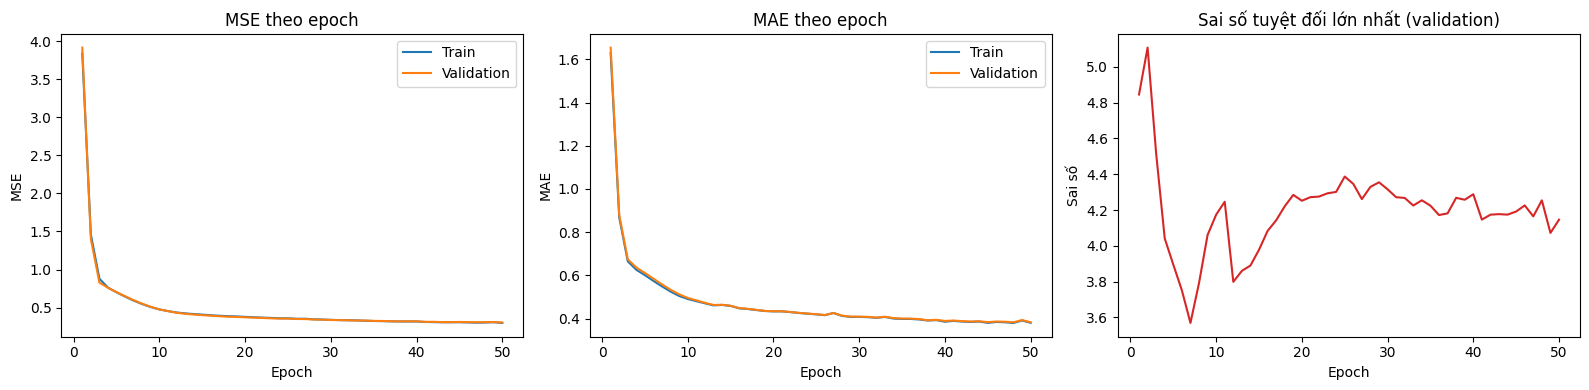

Đánh giá cuối trên tập test: {'mse': 0.3183095157146454, 'mae': 0.39132484793663025, 'max_ae': 4.172550201416016}


In [7]:
epochs = np.arange(1, n_epochs + 1)
figure, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(epochs, history["train_mse"], label="Train")
axes[0].plot(epochs, history["valid_mse"], label="Validation")
axes[0].set(title="MSE theo epoch", xlabel="Epoch", ylabel="MSE")
axes[0].legend()

axes[1].plot(epochs, history["train_mae"], label="Train")
axes[1].plot(epochs, history["valid_mae"], label="Validation")
axes[1].set(title="MAE theo epoch", xlabel="Epoch", ylabel="MAE")
axes[1].legend()

axes[2].plot(epochs, history["valid_max_ae"], color="tab:red")
axes[2].set(
    title="Sai số tuyệt đối lớn nhất (validation)",
    xlabel="Epoch",
    ylabel="Sai số",
)
figure.tight_layout()
plt.show()

model.eval()
with torch.inference_mode():
    test_metrics = regression_metrics(y_test_tensor, model(X_test_tensor))
print("Đánh giá cuối trên tập test:", test_metrics)

## **Cách đọc biểu đồ**

- `Train` và `validation` cùng giảm: mô hình đang học; nếu cả hai sớm phẳng, cân nhắc năng lực mô hình hoặc tốc độ học.
- `Train` tiếp tục giảm nhưng `validation` tăng: dấu hiệu quá khớp; cân nhắc regularization, giảm độ phức tạp hoặc early stopping.
- `Validation` dao động mạnh: kiểm tra learning rate, batch size và cách chia dữ liệu.
- `MAE` thể hiện mức sai số điển hình; maximum absolute error nhạy với ngoại lệ. Đối chiếu nhận xét với biểu đồ thực tế của lần chạy, vì dạng đường cong còn phụ thuộc cách chia dữ liệu và quá trình tối ưu.

# <center>**HẾT**<center>